In [1]:
!pip install -q librosa soundfile

import os, glob, subprocess

os.makedirs("audio_raw", exist_ok=True)   # your voice notes are here
os.makedirs("audio_wav", exist_ok=True)   # converted files appear here

files = sorted(glob.glob("audio_raw/*"))
print("Files found:", len(files))

for f in files:
    name = os.path.splitext(os.path.basename(f))[0]
    out = f"audio_wav/{name}.wav"
    subprocess.run(
        ["ffmpeg", "-y", "-i", f, "-ar", "16000", "-ac", "1", out],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
    )
    print("converted:", out)

Files found: 8
converted: audio_wav/Colombe_confirm_transaction.opus.wav
converted: audio_wav/Colombe_yes_approve.opus.wav
converted: audio_wav/Nelly_confirm_transaction.opus.wav
converted: audio_wav/Nelly_yes_approve.opus.wav
converted: audio_wav/Sahra_confirm_transaction.opus.wav
converted: audio_wav/Sahra_yes_approve.opus.wav
converted: audio_wav/Tifare_confirm_transaction.mp4.wav
converted: audio_wav/Tifare_yes_approve.mp4.wav


colombe  confirm_transaction    duration: 1.77s
colombe  yes_approve            duration: 1.41s
nelly    confirm_transaction    duration: 2.77s
nelly    yes_approve            duration: 1.97s
sahra    confirm_transaction    duration: 2.53s
sahra    yes_approve            duration: 2.91s
tifare   confirm_transaction    duration: 1.98s
tifare   yes_approve            duration: 1.81s


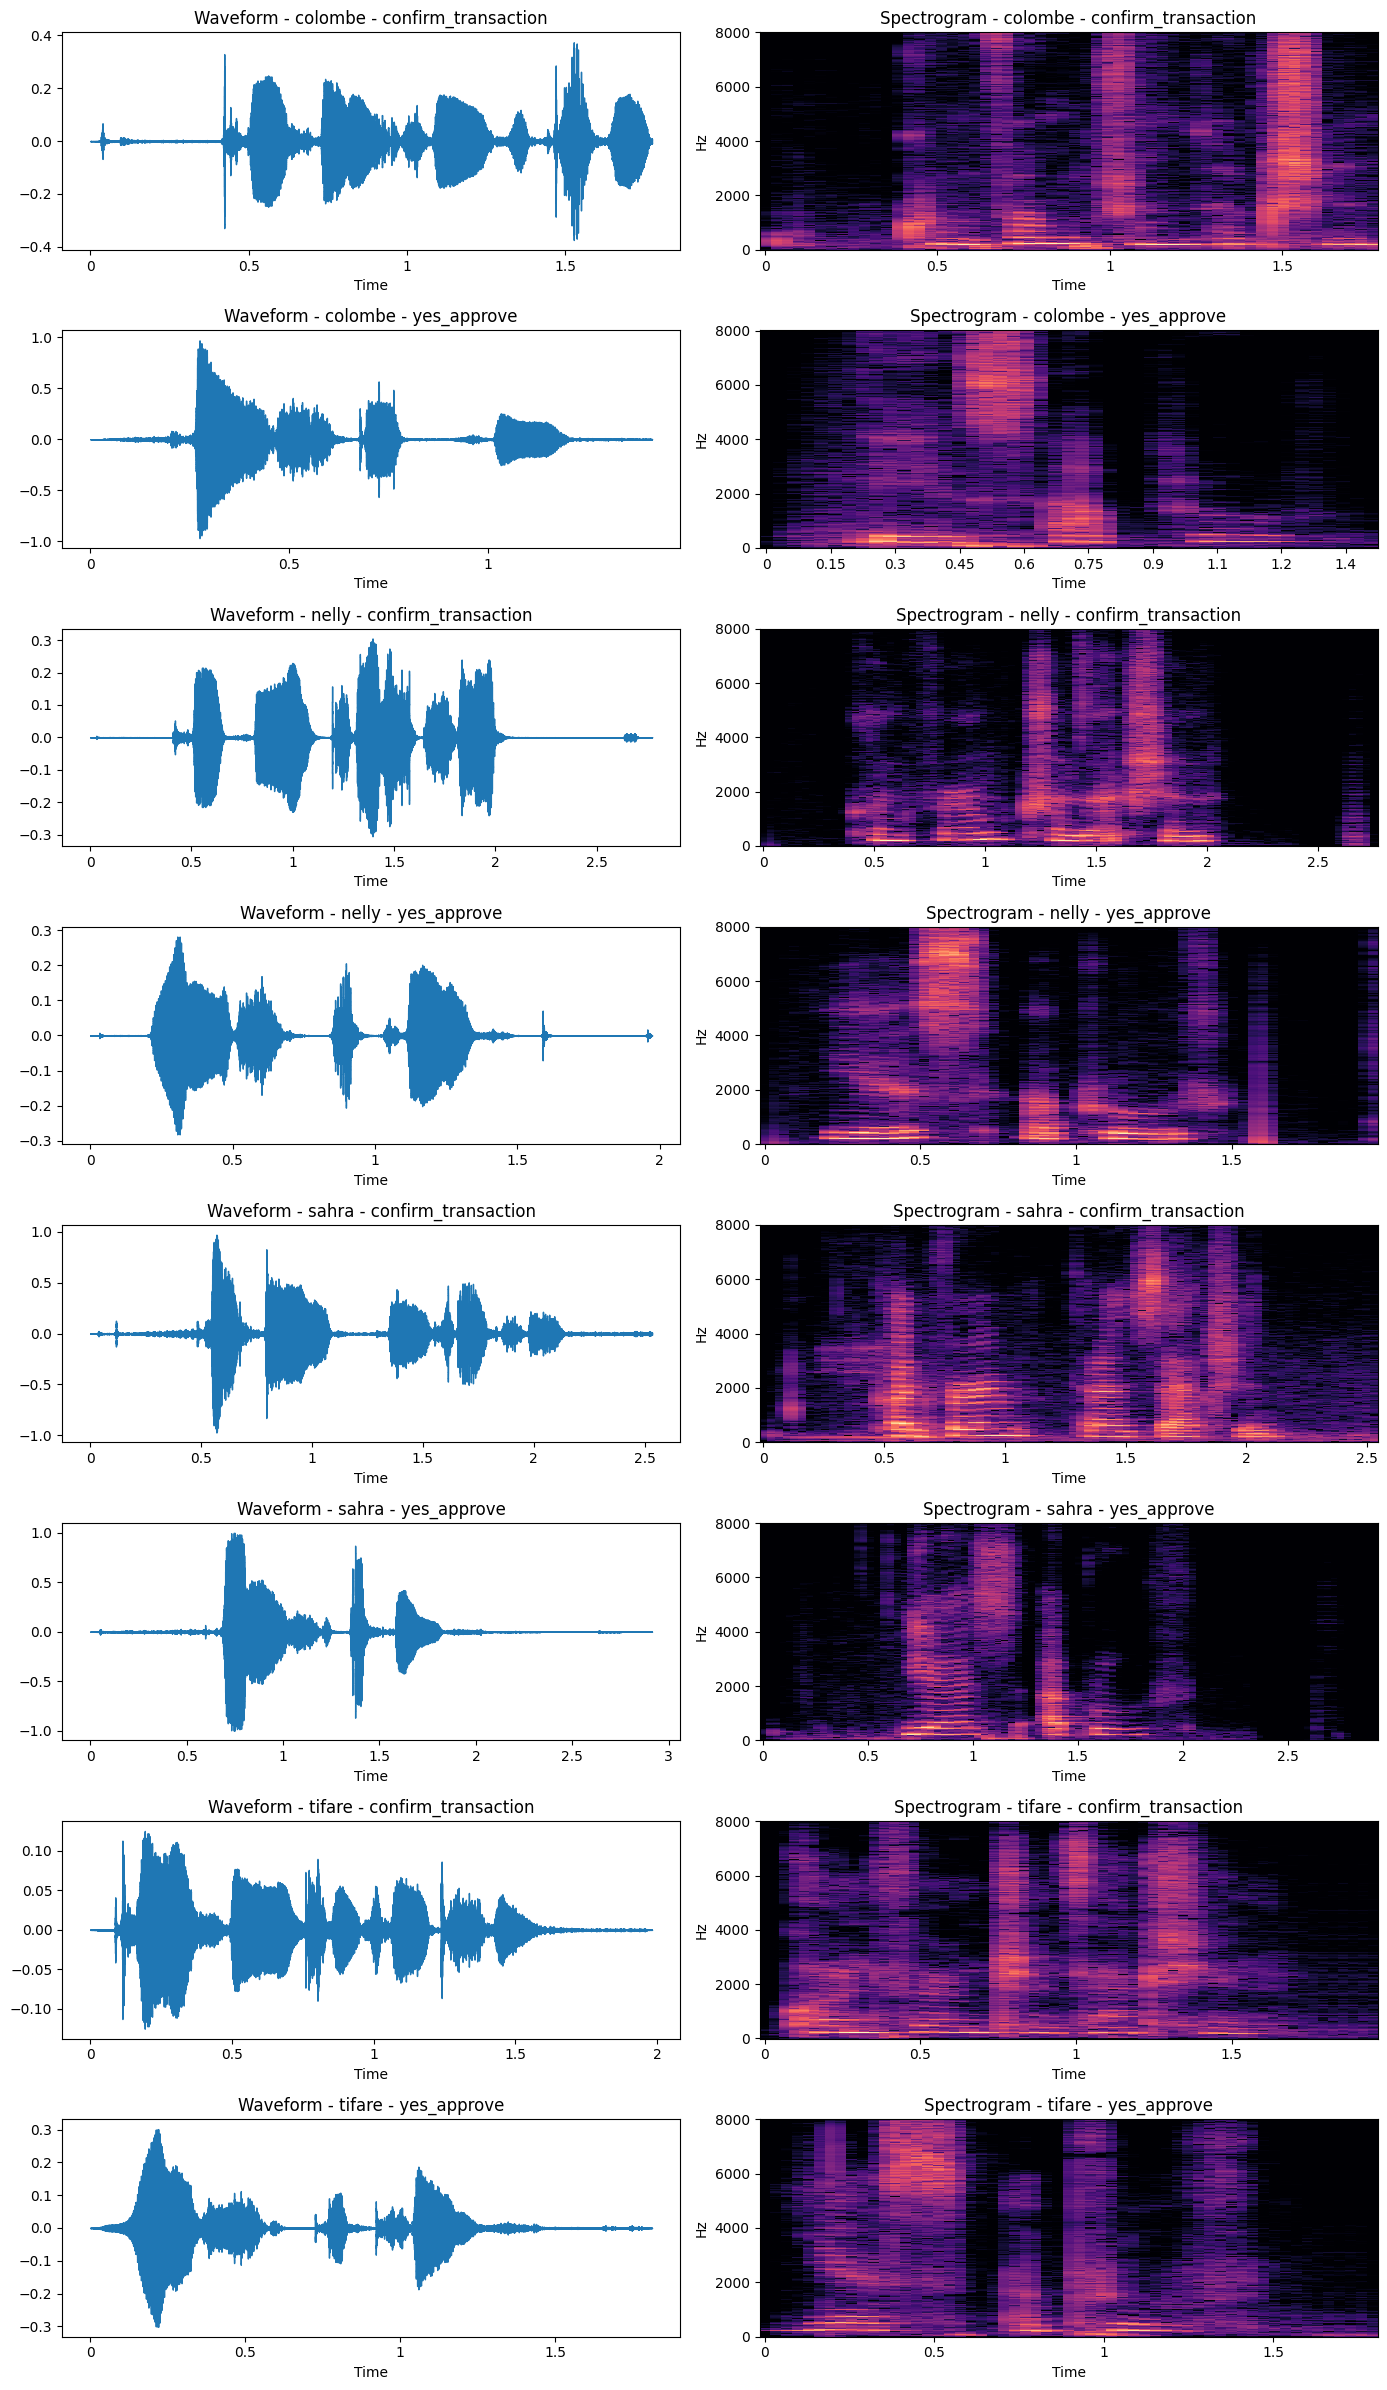

In [2]:
import glob, os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

def parse_name(path):
    base = os.path.basename(path).replace(".wav", "")
    base = base.replace(".opus", "").replace(".mp4", "")
    speaker, phrase = base.split("_", 1)
    return speaker.lower(), phrase

wav_files = sorted(glob.glob("audio_wav/*.wav"))

fig, axes = plt.subplots(len(wav_files), 2, figsize=(14, 3 * len(wav_files)))

for i, f in enumerate(wav_files):
    y, sr = librosa.load(f, sr=16000)
    speaker, phrase = parse_name(f)
    print(f"{speaker:8s} {phrase:22s} duration: {len(y)/sr:.2f}s")

    # Waveform
    librosa.display.waveshow(y, sr=sr, ax=axes[i, 0])
    axes[i, 0].set_title(f"Waveform - {speaker} - {phrase}")

    # Spectrogram
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="hz", ax=axes[i, 1])
    axes[i, 1].set_title(f"Spectrogram - {speaker} - {phrase}")

plt.tight_layout()
plt.show()

In [3]:
import glob, os
import numpy as np
import pandas as pd
import librosa
import soundfile as sf

np.random.seed(42)
os.makedirs("audio_aug", exist_ok=True)

def parse_name(path):
    base = os.path.basename(path).replace(".wav", "")
    base = base.replace(".opus", "").replace(".mp4", "")
    speaker, phrase = base.split("_", 1)
    return speaker.lower(), phrase

# --- Augmentations ---
def add_noise(y, sr):
    return y + 0.005 * np.random.randn(len(y)) * np.max(np.abs(y))

def pitch_shift(y, sr):
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=2)

def time_stretch(y, sr):
    return librosa.effects.time_stretch(y, rate=1.1)

augmentations = {
    "noise": add_noise,
    "pitch": pitch_shift,
    "stretch": time_stretch,
}

# --- Feature extraction ---
def extract_features(y, sr):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    rms = librosa.feature.rms(y=y)
    feats = {}
    for i in range(13):
        feats[f"mfcc{i+1}_mean"] = float(np.mean(mfcc[i]))
        feats[f"mfcc{i+1}_std"] = float(np.std(mfcc[i]))
    feats["rolloff_mean"] = float(np.mean(rolloff))
    feats["energy_mean"] = float(np.mean(rms))
    return feats

# --- Build the table ---
rows = []
for f in sorted(glob.glob("audio_wav/*.wav")):
    y, sr = librosa.load(f, sr=16000)
    speaker, phrase = parse_name(f)
    original_id = f"{speaker}_{phrase}"

    # original recording
    row = {"speaker": speaker, "phrase": phrase, "original_id": original_id,
           "augmentation": "none"}
    row.update(extract_features(y, sr))
    rows.append(row)

    # augmented copies
    for aug_name, aug_fn in augmentations.items():
        y_aug = aug_fn(y, sr)
        sf.write(f"audio_aug/{original_id}_{aug_name}.wav", y_aug, sr)
        row = {"speaker": speaker, "phrase": phrase, "original_id": original_id,
               "augmentation": aug_name}
        row.update(extract_features(y_aug, sr))
        rows.append(row)

df = pd.DataFrame(rows)
df.to_csv("audio_features.csv", index=False)

print("Shape:", df.shape)
print(df["speaker"].value_counts())
print(df[["speaker", "phrase", "augmentation", "rolloff_mean", "energy_mean"]].head(8))

Shape: (32, 32)
speaker
colombe    8
nelly      8
sahra      8
tifare     8
Name: count, dtype: int64
   speaker               phrase augmentation  rolloff_mean  energy_mean
0  colombe  confirm_transaction         none   2867.047991     0.055091
1  colombe  confirm_transaction        noise   4270.926339     0.055221
2  colombe  confirm_transaction        pitch   3119.838170     0.035087
3  colombe  confirm_transaction      stretch   3259.191176     0.040434
4  colombe          yes_approve         none   3286.111111     0.091694
5  colombe          yes_approve        noise   5118.923611     0.092497
6  colombe          yes_approve        pitch   3380.034722     0.064725
7  colombe          yes_approve      stretch   3402.057927     0.076757


In [4]:
import pandas as pd
import numpy as np
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix

df = pd.read_csv("audio_features.csv")
feature_cols = [c for c in df.columns if c.endswith("_mean") or c.endswith("_std")]
print("Number of features:", len(feature_cols))

def make_model():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=2000, C=1.0))

# --- Evaluation: train on one phrase, test on the other (originals only) ---
folds = [("yes_approve", "confirm_transaction"),
         ("confirm_transaction", "yes_approve")]

accs, f1s, losses = [], [], []
for train_phrase, test_phrase in folds:
    train = df[df["phrase"] == train_phrase]                      # originals + augmented
    test = df[(df["phrase"] == test_phrase) & (df["augmentation"] == "none")]

    model = make_model()
    model.fit(train[feature_cols], train["speaker"])

    pred = model.predict(test[feature_cols])
    proba = model.predict_proba(test[feature_cols])

    acc = accuracy_score(test["speaker"], pred)
    f1 = f1_score(test["speaker"], pred, average="macro")
    loss = log_loss(test["speaker"], proba, labels=model.classes_)
    accs.append(acc); f1s.append(f1); losses.append(loss)

    print(f"\nTrain on {train_phrase} -> test on {test_phrase}")
    print(f"  Accuracy: {acc:.3f} | F1 (macro): {f1:.3f} | Log loss: {loss:.3f}")
    print("  True     :", list(test["speaker"]))
    print("  Predicted:", list(pred))

print(f"\nAverage -> Accuracy: {np.mean(accs):.3f} | F1: {np.mean(f1s):.3f} | Log loss: {np.mean(losses):.3f}")

# --- Final model for the CLI: trained on ALL data ---
final_model = make_model()
final_model.fit(df[feature_cols], df["speaker"])
joblib.dump({"model": final_model, "features": feature_cols}, "voice_model.pkl")
print("\nSaved voice_model.pkl")

Number of features: 28

Train on yes_approve -> test on confirm_transaction
  Accuracy: 0.750 | F1 (macro): 0.667 | Log loss: 0.306
  True     : ['colombe', 'nelly', 'sahra', 'tifare']
  Predicted: ['colombe', 'sahra', 'sahra', 'tifare']

Train on confirm_transaction -> test on yes_approve
  Accuracy: 0.750 | F1 (macro): 0.667 | Log loss: 0.633
  True     : ['colombe', 'nelly', 'sahra', 'tifare']
  Predicted: ['colombe', 'nelly', 'sahra', 'sahra']

Average -> Accuracy: 0.750 | F1: 0.667 | Log loss: 0.470

Saved voice_model.pkl


In [5]:
import pandas as pd
import numpy as np
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

df = pd.read_csv("audio_features.csv")
feature_cols = [c for c in df.columns if c.endswith("_mean") or c.endswith("_std")]
speakers = sorted(df["speaker"].unique())

def make_model():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=2000, C=1.0))

folds = [("yes_approve", "confirm_transaction"),
         ("confirm_transaction", "yes_approve")]

auth_scores, wrong_scores, unknown_scores = [], [], []

# A) Known speakers: train on one phrase, test on the other phrase (originals only)
for train_phrase, test_phrase in folds:
    train = df[df["phrase"] == train_phrase]
    test = df[(df["phrase"] == test_phrase) & (df["augmentation"] == "none")]
    model = make_model().fit(train[feature_cols], train["speaker"])
    classes = list(model.classes_)
    proba = model.predict_proba(test[feature_cols])
    for true_spk, p in zip(test["speaker"], proba):
        for claimed in speakers:
            score = p[classes.index(claimed)]
            if claimed == true_spk:
                auth_scores.append(score)    # authorized attempt
            else:
                wrong_scores.append(score)   # known wrong voice

# B) Unknown voice: remove one speaker from training, test them as a stranger
for unknown in speakers:
    train = df[df["speaker"] != unknown]
    test = df[(df["speaker"] == unknown) & (df["augmentation"] == "none")]
    model = make_model().fit(train[feature_cols], train["speaker"])
    classes = list(model.classes_)
    proba = model.predict_proba(test[feature_cols])
    for p in proba:
        for claimed in classes:
            unknown_scores.append(p[classes.index(claimed)])

auth_scores = np.array(auth_scores)
wrong_scores = np.array(wrong_scores)
unknown_scores = np.array(unknown_scores)

print("Attempts -> authorized:", len(auth_scores),
      "| known wrong voice:", len(wrong_scores),
      "| unknown voice:", len(unknown_scores))

rows = []
for thr in [0.5, 0.6, 0.7, 0.8, 0.9]:
    rows.append({
        "threshold": thr,
        "false_reject_rate": float(np.mean(auth_scores < thr)),
        "false_accept_wrong_known": float(np.mean(wrong_scores >= thr)),
        "false_accept_unknown": float(np.mean(unknown_scores >= thr)),
    })
table = pd.DataFrame(rows)
table["total_error"] = (table["false_reject_rate"]
                        + table["false_accept_wrong_known"]
                        + table["false_accept_unknown"])
print(table.round(3).to_string(index=False))

# Pick the threshold with the lowest total error (highest threshold wins ties)
best = table.sort_values(["total_error", "threshold"], ascending=[True, False]).iloc[0]
best_thr = float(best["threshold"])
print("\nChosen threshold:", best_thr)

# Add the threshold to the saved voice model
bundle = joblib.load("voice_model.pkl")
bundle["threshold"] = best_thr
joblib.dump(bundle, "voice_model.pkl")
table.to_csv("voice_rejection_results.csv", index=False)
print("Updated voice_model.pkl and saved voice_rejection_results.csv")

Attempts -> authorized: 8 | known wrong voice: 24 | unknown voice: 24
 threshold  false_reject_rate  false_accept_wrong_known  false_accept_unknown  total_error
       0.5              0.375                     0.042                 0.292        0.708
       0.6              0.375                     0.000                 0.208        0.583
       0.7              0.625                     0.000                 0.167        0.792
       0.8              0.625                     0.000                 0.167        0.792
       0.9              0.750                     0.000                 0.167        0.917

Chosen threshold: 0.6
Updated voice_model.pkl and saved voice_rejection_results.csv


In [14]:
%%writefile voice_verification.py
import os, subprocess, tempfile
import numpy as np
import pandas as pd
import librosa
import joblib

def _extract(y, sr):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    rms = librosa.feature.rms(y=y)
    feats = {}
    for i in range(13):
        feats[f"mfcc{i+1}_mean"] = float(np.mean(mfcc[i]))
        feats[f"mfcc{i+1}_std"] = float(np.std(mfcc[i]))
    feats["rolloff_mean"] = float(np.mean(rolloff))
    feats["energy_mean"] = float(np.mean(rms))
    return feats

def verify_voice(audio_path, claimed_speaker, model_path="voice_model.pkl"):
    """Returns a dict: approved (bool), score, predicted, claimed, threshold."""
    if not os.path.exists(audio_path):
        raise FileNotFoundError(f"Audio file not found: {audio_path}")

    bundle = joblib.load(model_path)
    model, cols, thr = bundle["model"], bundle["features"], bundle["threshold"]

    # convert any audio format (wav, opus, mp4, m4a, mp3) to 16 kHz mono wav
    tmp = tempfile.NamedTemporaryFile(suffix=".wav", delete=False).name
    result = subprocess.run(["ffmpeg", "-y", "-i", audio_path, "-ar", "16000", "-ac", "1", tmp],
                            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    if result.returncode != 0:
        raise RuntimeError(f"Could not convert audio file: {audio_path}")
    y, sr = librosa.load(tmp, sr=16000)
    os.remove(tmp)

    feats = _extract(y, sr)
    x = pd.DataFrame([feats])[cols]
    proba = model.predict_proba(x)[0]
    classes = list(model.classes_)
    claimed = claimed_speaker.lower()
    score = float(proba[classes.index(claimed)]) if claimed in classes else 0.0
    predicted = classes[int(np.argmax(proba))]
    return {"approved": score >= thr, "score": round(score, 3),
            "predicted": predicted, "claimed": claimed, "threshold": thr}

Overwriting voice_verification.py


In [15]:
import glob
from voice_verification import verify_voice

def find(name):
    return sorted(glob.glob(f"audio_raw/{name}*"))[0]

print("Authorized (Nelly's voice, Nelly's face):")
print(verify_voice(find("Nelly_yes_approve"), "nelly"))

print("\nUnauthorized (Sahra's voice, Nelly's face):")
print(verify_voice(find("Sahra_yes_approve"), "nelly"))

print("\nUnauthorized (Tifare's voice, Colombe's face):")
print(verify_voice(find("Tifare_confirm_transaction"), "colombe"))

Authorized (Nelly's voice, Nelly's face):


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


{'approved': True, 'score': 0.985, 'predicted': 'nelly', 'claimed': 'nelly', 'threshold': 0.6}

Unauthorized (Sahra's voice, Nelly's face):


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


{'approved': False, 'score': 0.013, 'predicted': 'sahra', 'claimed': 'nelly', 'threshold': 0.6}

Unauthorized (Tifare's voice, Colombe's face):
{'approved': False, 'score': 0.006, 'predicted': 'tifare', 'claimed': 'colombe', 'threshold': 0.6}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
